/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


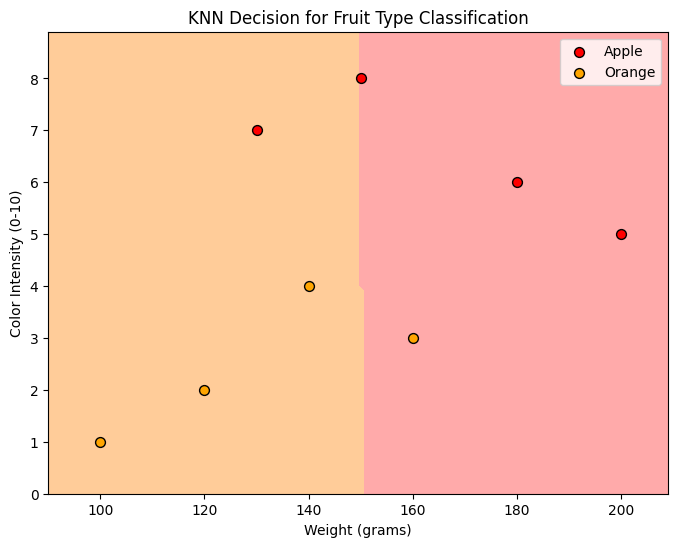

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from matplotlib.colors import ListedColormap

# Load the dataset
data = {
    "Weight (grams)": [150, 130, 180, 200, 120, 160, 140, 100],
    "Color Intensity (0-10)": [8, 7, 6, 5, 2, 3, 4, 1],
    "Fruit Type": ["Apple", "Apple", "Apple", "Apple", "Orange", "Orange", "Orange", "Orange"]
}
df = pd.DataFrame(data)

# Convert labels to numerical values for modeling
df["Fruit Type"] = df["Fruit Type"].map({"Apple": 0, "Orange": 1})

# Features and labels
X = df[["Weight (grams)", "Color Intensity (0-10)"]]
y = df["Fruit Type"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize KNN model
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Plot decision boundary
x_min, x_max = X["Weight (grams)"].min() - 10, X["Weight (grams)"].max() + 10
y_min, y_max = X["Color Intensity (0-10)"].min() - 1, X["Color Intensity (0-10)"].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 1), np.arange(y_min, y_max, 0.1))

# Predict labels for the mesh grid points
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Create a color map
cmap_light = ListedColormap(['#FFAAAA', '#FFCC99'])  # Light red and light orange
cmap_bold = ['red', 'orange']  # Red for apple, orange for orange

# Plotting
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, cmap=cmap_light)

# Plot training points
for idx, color in enumerate(cmap_bold):
    plt.scatter(X.loc[y == idx, "Weight (grams)"], X.loc[y == idx, "Color Intensity (0-10)"],
                c=color, label=["Apple", "Orange"][idx], edgecolor='k', s=50)
plt.xlabel("Weight (grams)")
plt.ylabel("Color Intensity (0-10)")
plt.legend()
plt.title("KNN Decision for Fruit Type Classification")
plt.show()
